Device: cuda
GPU: Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.6MB/s]


Train: (55000, 784)
Val:   (5000, 784)
Test:  (10000, 784)
Pixel range: 0.0 to 1.0


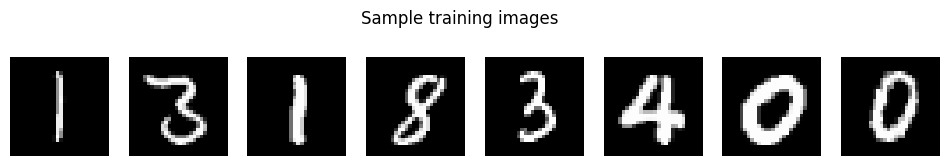

In [1]:
import time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

# ---------- Device ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ---------- Reproducibility ----------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)

# ---------- Load MNIST ----------
train_full = datasets.MNIST(root="./data", train=True, download=True)
test_set   = datasets.MNIST(root="./data", train=False, download=True)

# Pixels scaled to [0, 1], flattened to 784-dim vectors
X_full = train_full.data.float().div(255.0).view(-1, 784)   # (60000, 784)
X_test = test_set.data.float().div(255.0).view(-1, 784)     # (10000, 784)

# ---------- Split: 55k train / 5k val (fixed split) / 10k test ----------
g = torch.Generator().manual_seed(123)
perm = torch.randperm(X_full.size(0), generator=g)
X_train = X_full[perm[:55000]].to(device)
X_val   = X_full[perm[55000:]].to(device)
X_test  = X_test.to(device)

print("Train:", tuple(X_train.shape))
print("Val:  ", tuple(X_val.shape))
print("Test: ", tuple(X_test.shape))
print("Pixel range:", X_train.min().item(), "to", X_train.max().item())

# ---------- Quick visual check ----------
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].cpu().view(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

In [2]:
# ---------- Shared architecture: 784 -> 256 -> 64 -> 256 -> 784 ----------
dims = [784, 256, 64, 256, 784]

class AE(nn.Module):
    """Tanh hidden layers, Sigmoid output. Same class/init for BP and PC."""
    def __init__(self, dims=dims):
        super().__init__()
        self.layers = nn.ModuleList(
            [nn.Linear(dims[i], dims[i + 1]) for i in range(len(dims) - 1)]
        )
        for l in self.layers:
            nn.init.xavier_uniform_(l.weight)
            nn.init.zeros_(l.bias)

    def act(self, i, z):
        # last layer -> sigmoid, all others -> tanh
        return torch.sigmoid(z) if i == len(self.layers) - 1 else torch.tanh(z)

    def forward(self, x):
        for i, l in enumerate(self.layers):
            x = self.act(i, l(x))
        return x

def make_model(seed):
    set_seed(seed)
    return AE().to(device)

# ---------- Metrics ----------
def _gaussian_window(size=11, sigma=1.5):
    coords = torch.arange(size).float() - size // 2
    g = torch.exp(-coords ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :])[None, None].to(device)

_WIN = _gaussian_window()

def ssim_per_image(x, y):
    """x, y: (N, 784) in [0,1]. Returns SSIM per image, shape (N,)."""
    x = x.view(-1, 1, 28, 28)
    y = y.view(-1, 1, 28, 28)
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    mu_x = F.conv2d(x, _WIN)
    mu_y = F.conv2d(y, _WIN)
    sig_x = F.conv2d(x * x, _WIN) - mu_x ** 2
    sig_y = F.conv2d(y * y, _WIN) - mu_y ** 2
    sig_xy = F.conv2d(x * y, _WIN) - mu_x * mu_y
    s = ((2 * mu_x * mu_y + C1) * (2 * sig_xy + C2)) / \
        ((mu_x ** 2 + mu_y ** 2 + C1) * (sig_x + sig_y + C2))
    return s.mean(dim=(1, 2, 3))

@torch.no_grad()
def evaluate(recon_fn, X, batch=1000):
    """recon_fn: maps (N,784) images -> (N,784) reconstructions.
    Works for BP (model forward) and later for PC (inference + readout)."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, X.size(0), batch):
        x = X[i:i + batch]
        y = recon_fn(x)
        mse = ((x - y) ** 2).mean(dim=1)
        psnr = 10 * torch.log10(1.0 / mse.clamp_min(1e-10))
        mses.append(mse); psnrs.append(psnr); ssims.append(ssim_per_image(x, y))
    return {
        "mse":  torch.cat(mses).mean().item(),
        "psnr": torch.cat(psnrs).mean().item(),
        "ssim": torch.cat(ssims).mean().item(),
    }

# ---------- Quick checks ----------
model = make_model(0)
n_params = sum(p.numel() for p in model.parameters())
print("Parameters:", n_params)

out = model(X_val[:5])
print("Output shape:", tuple(out.shape), "| range:", out.min().item(), "to", out.max().item())

print("SSIM(x, x) should be ~1:", ssim_per_image(X_val[:100], X_val[:100]).mean().item())
print("Untrained model on val:", evaluate(model, X_val))

Parameters: 435536
Output shape: (5, 784) | range: 0.3282719552516937 to 0.6579680442810059
SSIM(x, x) should be ~1: 1.0
Untrained model on val: {'mse': 0.23341943323612213, 'psnr': 6.319478511810303, 'ssim': 0.004978010430932045}


BP ep  1 | train 0.05223 | val 0.03199 | 1.1s
BP ep  2 | train 0.02473 | val 0.01921 | 0.8s
BP ep  3 | train 0.01613 | val 0.01373 | 0.8s
BP ep  4 | train 0.01225 | val 0.01094 | 0.8s
BP ep  5 | train 0.01001 | val 0.00950 | 0.8s
BP ep  6 | train 0.00867 | val 0.00823 | 0.8s
BP ep  7 | train 0.00765 | val 0.00741 | 0.8s
BP ep  8 | train 0.00693 | val 0.00686 | 0.8s
BP ep  9 | train 0.00642 | val 0.00636 | 0.9s
BP ep 10 | train 0.00603 | val 0.00611 | 0.9s
BP val metrics: {'mse': 0.006107218097895384, 'psnr': 22.95853042602539, 'ssim': 0.9113078117370605}


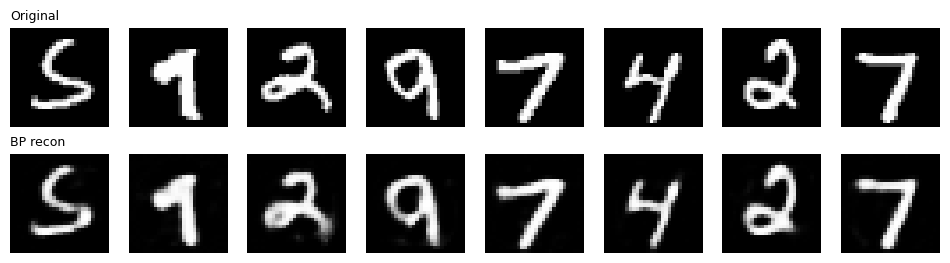

In [3]:
# ---------- BP training ----------
def train_bp(seed, lr=1e-3, epochs=10, batch_size=128, verbose=True):
    model = make_model(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator(device=device).manual_seed(seed)   # controls batch order
    N = X_train.size(0)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}

    for ep in range(epochs):
        model.train()
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()

        perm = torch.randperm(N, device=device, generator=g)
        total = 0.0
        for i in range(0, N, batch_size):
            x = X_train[perm[i:i + batch_size]]
            loss = F.mse_loss(model(x), x)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.item() * x.size(0)

        if device.type == "cuda": torch.cuda.synchronize()
        epoch_time = time.time() - t0

        model.eval()
        with torch.no_grad():
            val_loss = F.mse_loss(model(X_val), X_val).item()

        hist["train_loss"].append(total / N)
        hist["val_loss"].append(val_loss)
        hist["epoch_time"].append(epoch_time)
        if verbose:
            print(f"BP ep {ep+1:2d} | train {total/N:.5f} | val {val_loss:.5f} | {epoch_time:.1f}s")

    return model, hist

# ---------- Run one BP model as a test ----------
bp_model, bp_hist = train_bp(seed=0)

bp_model.eval()
print("BP val metrics:", evaluate(bp_model, X_val))

# ---------- Quick look at reconstructions ----------
with torch.no_grad():
    rec = bp_model(X_val[:8]).cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(X_val[i].cpu().view(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(rec[i].view(28, 28), cmap="gray");         axes[1, i].axis("off")
axes[0, 0].set_title("Original", fontsize=9, loc="left")
axes[1, 0].set_title("BP recon", fontsize=9, loc="left")
plt.show()

--- T=20, eta=0.1 ---
layer 0: cosine 0.9699 | norm ratio PC/BP 0.137
layer 1: cosine 0.9676 | norm ratio PC/BP 0.254
layer 2: cosine 0.9515 | norm ratio PC/BP 0.719
layer 3: cosine 0.7464 | norm ratio PC/BP 1.100
--- T=100, eta=0.1 ---
layer 0: cosine 0.9734 | norm ratio PC/BP 0.551
layer 1: cosine 0.9622 | norm ratio PC/BP 0.594
layer 2: cosine 0.7233 | norm ratio PC/BP 0.881
layer 3: cosine 0.4524 | norm ratio PC/BP 1.324
PC ep  1 | train 0.04474 | val 0.02264 | 7.6s
PC ep  2 | train 0.01651 | val 0.01263 | 6.9s
PC ep  3 | train 0.01065 | val 0.00931 | 7.6s
PC ep  4 | train 0.00842 | val 0.00780 | 7.2s
PC ep  5 | train 0.00716 | val 0.00678 | 7.5s
PC ep  6 | train 0.00640 | val 0.00632 | 7.7s
PC ep  7 | train 0.00591 | val 0.00623 | 7.5s
PC ep  8 | train 0.00562 | val 0.00576 | 7.6s
PC ep  9 | train 0.00543 | val 0.00553 | 6.8s
PC ep 10 | train 0.00534 | val 0.00552 | 7.8s
PC val metrics: {'mse': 0.005516819655895233, 'psnr': 23.396270751953125, 'ssim': 0.9229201078414917}
BP val me

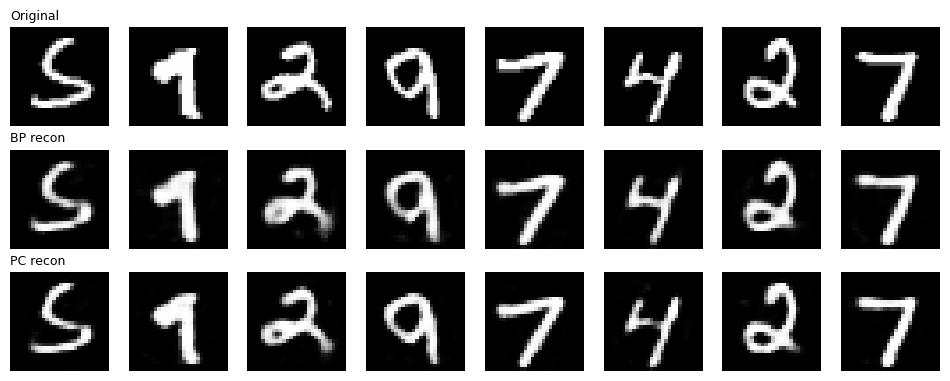

In [4]:
# ---------- Predictive Coding (same AE, same init, same optimizer as BP) ----------
L = len(dims) - 1   # 4 weight layers -> states x_0 ... x_4

def act_deriv(i, mu):
    # derivative of the activation, written in terms of its output mu
    return mu * (1 - mu) if i == L - 1 else 1 - mu ** 2

@torch.no_grad()
def pc_infer(model, x_in, x_target, T=20, eta=0.1):
    """Clamp x_0 = x_in and x_L = x_target; settle hidden states by gradient descent on energy."""
    # initialise states with a feedforward pass
    states = [x_in]
    h = x_in
    for i in range(L - 1):
        h = model.act(i, model.layers[i](h))
        states.append(h)
    ff_out = model.act(L - 1, model.layers[L - 1](h))   # feedforward reconstruction
    states.append(x_target)

    for _ in range(T):
        errs, deltas = [], []
        for i in range(L):
            mu = model.act(i, model.layers[i](states[i]))
            e = states[i + 1] - mu
            errs.append(e)
            deltas.append(e * act_deriv(i, mu))
        # dF/dx_k = e_k - W_k^T (e_{k+1} * f'), for the free states k = 1..L-1
        for k in range(1, L):
            grad = errs[k - 1] - deltas[k] @ model.layers[k].weight
            states[k] = states[k] - eta * grad
    return states, ff_out

@torch.no_grad()
def pc_weight_grads(model, states):
    """Local weight gradients dF/dW = -(e * f') x_prev^T, scaled by 2/784 to match F.mse_loss."""
    scale = 2.0 / 784
    for i, l in enumerate(model.layers):
        mu = model.act(i, l(states[i]))
        delta = (states[i + 1] - mu) * act_deriv(i, mu)
        B = states[i].size(0)
        l.weight.grad = -(delta.T @ states[i]) / B * scale
        l.bias.grad = -delta.mean(dim=0) * scale

@torch.no_grad()
def pc_recon(model, x):
    # only the input is clamped -> energy minimum is the feedforward pass
    return model(x)

# ---------- Sanity check: PC gradients vs BP gradients ----------
def grad_check(T, eta=0.1, seed=0, n=256):
    m = make_model(seed)
    x = X_train[:n]
    m.zero_grad()
    F.mse_loss(m(x), x).backward()
    bp = [l.weight.grad.clone() for l in m.layers]
    states, _ = pc_infer(m, x, x, T, eta)
    pc_weight_grads(m, states)
    print(f"--- T={T}, eta={eta} ---")
    for i, l in enumerate(m.layers):
        cos = F.cosine_similarity(l.weight.grad.flatten(), bp[i].flatten(), dim=0).item()
        ratio = (l.weight.grad.norm() / bp[i].norm()).item()
        print(f"layer {i}: cosine {cos:.4f} | norm ratio PC/BP {ratio:.3f}")

grad_check(T=20)
grad_check(T=100)

# ---------- PC training (mirrors train_bp) ----------
def train_pc(seed, lr=1e-3, epochs=10, batch_size=128, T=20, eta=0.1, verbose=True):
    model = make_model(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator(device=device).manual_seed(seed)
    N = X_train.size(0)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}

    for ep in range(epochs):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()

        perm = torch.randperm(N, device=device, generator=g)
        total = 0.0
        for i in range(0, N, batch_size):
            x = X_train[perm[i:i + batch_size]]
            states, ff_out = pc_infer(model, x, x, T, eta)
            pc_weight_grads(model, states)
            opt.step()
            total += F.mse_loss(ff_out, x).item() * x.size(0)

        if device.type == "cuda": torch.cuda.synchronize()
        epoch_time = time.time() - t0

        val_loss = F.mse_loss(pc_recon(model, X_val), X_val).item()
        hist["train_loss"].append(total / N)
        hist["val_loss"].append(val_loss)
        hist["epoch_time"].append(epoch_time)
        if verbose:
            print(f"PC ep {ep+1:2d} | train {total/N:.5f} | val {val_loss:.5f} | {epoch_time:.1f}s")
    return model, hist

# ---------- Run one PC model as a test ----------
pc_model, pc_hist = train_pc(seed=0)
print("PC val metrics:", evaluate(lambda x: pc_recon(pc_model, x), X_val))
print("BP val metrics:", evaluate(bp_model, X_val))

# ---------- Visual comparison ----------
with torch.no_grad():
    rec_bp = bp_model(X_val[:8]).cpu()
    rec_pc = pc_recon(pc_model, X_val[:8]).cpu()
fig, axes = plt.subplots(3, 8, figsize=(12, 4.5))
for i in range(8):
    axes[0, i].imshow(X_val[i].cpu().view(28, 28), cmap="gray")
    axes[1, i].imshow(rec_bp[i].view(28, 28), cmap="gray")
    axes[2, i].imshow(rec_pc[i].view(28, 28), cmap="gray")
    for r in range(3): axes[r, i].axis("off")
axes[0, 0].set_title("Original", fontsize=9, loc="left")
axes[1, 0].set_title("BP recon", fontsize=9, loc="left")
axes[2, 0].set_title("PC recon", fontsize=9, loc="left")
plt.show()

In [5]:
# ---------- Equal-budget tuning: 3 learning rates per method, selected on validation ----------
lrs = [5e-4, 1e-3, 2e-3]
tune = {"BP": {}, "PC": {}}

for lr in lrs:
    m, h = train_bp(seed=0, lr=lr, verbose=False)
    tune["BP"][lr] = h["val_loss"][-1]
    print(f"BP lr={lr:.0e} | final val MSE {h['val_loss'][-1]:.5f}")

for lr in lrs:
    m, h = train_pc(seed=0, lr=lr, T=20, eta=0.1, verbose=False)
    tune["PC"][lr] = h["val_loss"][-1]
    print(f"PC lr={lr:.0e} | final val MSE {h['val_loss'][-1]:.5f}")

best_lr_bp = min(tune["BP"], key=tune["BP"].get)
best_lr_pc = min(tune["PC"], key=tune["PC"].get)
print("\nBest BP lr:", best_lr_bp, "| Best PC lr:", best_lr_pc)

BP lr=5e-04 | final val MSE 0.00647
BP lr=1e-03 | final val MSE 0.00611
BP lr=2e-03 | final val MSE 0.00744
PC lr=5e-04 | final val MSE 0.00599
PC lr=1e-03 | final val MSE 0.00552
PC lr=2e-03 | final val MSE 0.00727

Best BP lr: 0.001 | Best PC lr: 0.001


In [6]:
from scipy import stats

seeds = [0, 1, 2, 3, 4]
runs = {"BP": [], "PC": []}   # each entry: (model, history, test_metrics)

for s in seeds:
    m, h = train_bp(seed=s, lr=best_lr_bp, verbose=False)
    m.eval()
    runs["BP"].append((m, h, evaluate(m, X_test)))
    print(f"BP seed {s} | test MSE {runs['BP'][-1][2]['mse']:.5f}")

for s in seeds:
    m, h = train_pc(seed=s, lr=best_lr_pc, T=20, eta=0.1, verbose=False)
    runs["PC"].append((m, h, evaluate(lambda x, m=m: pc_recon(m, x), X_test)))
    print(f"PC seed {s} | test MSE {runs['PC'][-1][2]['mse']:.5f}")

# ---------- Summary table (mean ± std across seeds) ----------
def collect(method, key):
    return np.array([r[2][key] for r in runs[method]])

def epoch_time(method):
    # mean time per epoch, skipping epoch 1 (GPU warm-up)
    return np.array([np.mean(r[1]["epoch_time"][1:]) for r in runs[method]])

print("\n=== TEST SET RESULTS (mean ± std over", len(seeds), "seeds) ===")
print(f"{'Method':<6} {'MSE':>18} {'PSNR (dB)':>18} {'SSIM':>18} {'s/epoch':>14}")
for method in ["BP", "PC"]:
    mse, psnr, ssim, et = collect(method, "mse"), collect(method, "psnr"), collect(method, "ssim"), epoch_time(method)
    print(f"{method:<6} {mse.mean():>10.5f} ± {mse.std():.5f} {psnr.mean():>9.2f} ± {psnr.std():.2f} "
          f"{ssim.mean():>9.4f} ± {ssim.std():.4f} {et.mean():>8.2f} ± {et.std():.2f}")

# ---------- Paired t-test on test MSE (same seed = same init and batch order) ----------
t, p = stats.ttest_rel(collect("BP", "mse"), collect("PC", "mse"))
print(f"\nPaired t-test on test MSE (BP vs PC): t = {t:.2f}, p = {p:.4f}")
print(f"PC slowdown per epoch: {epoch_time('PC').mean() / epoch_time('BP').mean():.1f}x")

BP seed 0 | test MSE 0.00587
BP seed 1 | test MSE 0.00565
BP seed 2 | test MSE 0.00586
BP seed 3 | test MSE 0.00567
BP seed 4 | test MSE 0.00615
PC seed 0 | test MSE 0.00533
PC seed 1 | test MSE 0.00525
PC seed 2 | test MSE 0.00529
PC seed 3 | test MSE 0.00546
PC seed 4 | test MSE 0.00530

=== TEST SET RESULTS (mean ± std over 5 seeds) ===
Method                MSE          PSNR (dB)               SSIM        s/epoch
BP        0.00584 ± 0.00018     23.15 ± 0.13    0.9143 ± 0.0015     0.83 ± 0.06
PC        0.00532 ± 0.00007     23.53 ± 0.06    0.9227 ± 0.0019     7.44 ± 0.20

Paired t-test on test MSE (BP vs PC): t = 4.90, p = 0.0080
PC slowdown per epoch: 8.9x


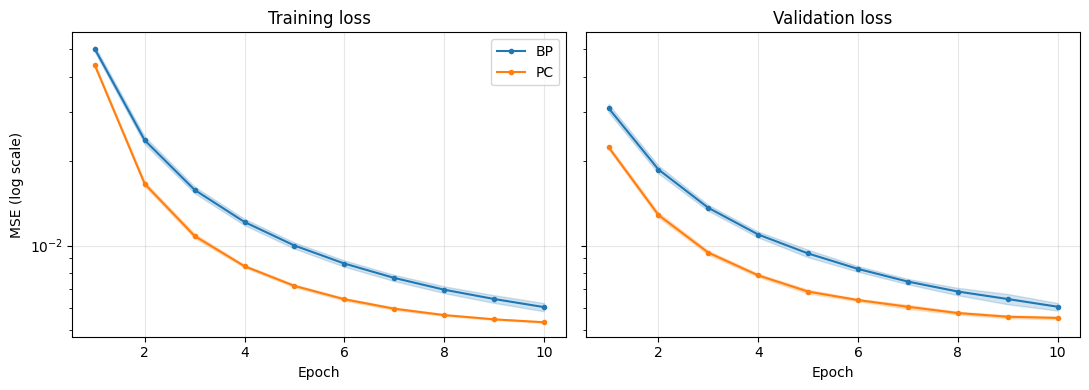

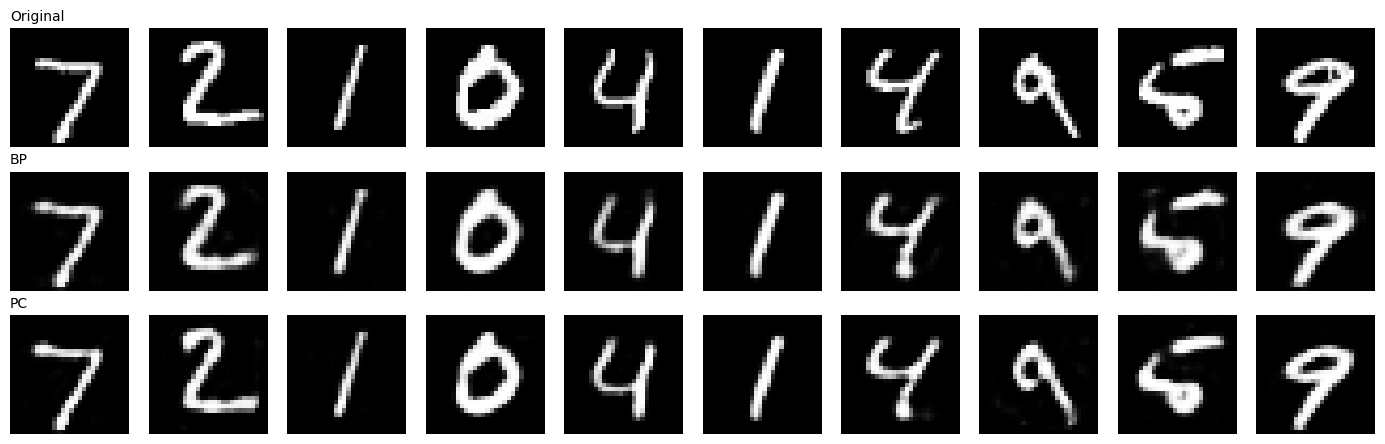

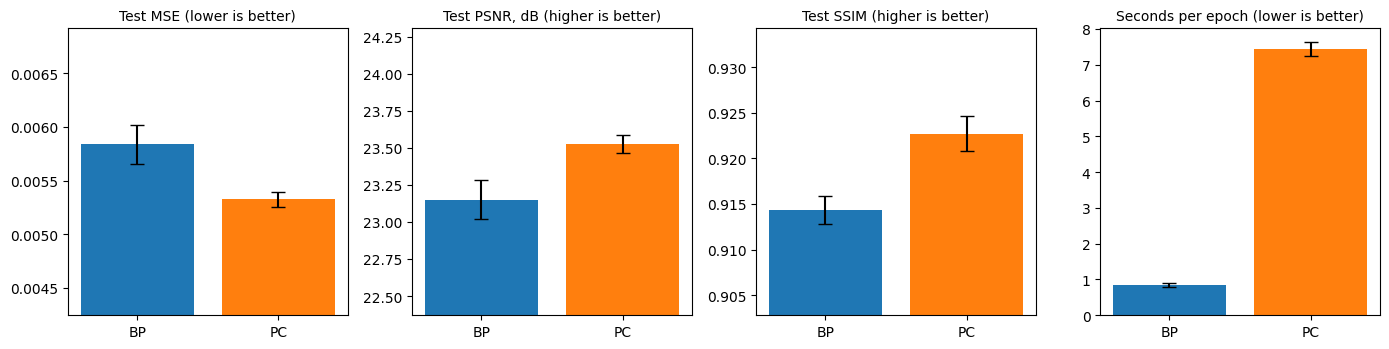

In [7]:
# ---------- Figure 1: training / validation curves (mean ± std over seeds) ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {"BP": "tab:blue", "PC": "tab:orange"}
epochs_x = np.arange(1, len(runs["BP"][0][1]["train_loss"]) + 1)

for ax, key, title in zip(axes, ["train_loss", "val_loss"], ["Training loss", "Validation loss"]):
    for method in ["BP", "PC"]:
        arr = np.array([r[1][key] for r in runs[method]])
        mean, std = arr.mean(0), arr.std(0)
        ax.plot(epochs_x, mean, label=method, color=colors[method], marker="o", ms=3)
        ax.fill_between(epochs_x, mean - std, mean + std, color=colors[method], alpha=0.2)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_yscale("log"); ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (log scale)")
axes[0].legend()
plt.tight_layout()
plt.savefig("fig1_loss_curves.png", dpi=150)
plt.show()

# ---------- Figure 2: reconstruction grid on TEST images (seed-0 models) ----------
n = 10
bp0 = runs["BP"][0][0]; pc0 = runs["PC"][0][0]
with torch.no_grad():
    rec_bp = bp0(X_test[:n]).cpu()
    rec_pc = pc_recon(pc0, X_test[:n]).cpu()

fig, axes = plt.subplots(3, n, figsize=(1.4 * n, 4.5))
for i in range(n):
    axes[0, i].imshow(X_test[i].cpu().view(28, 28), cmap="gray")
    axes[1, i].imshow(rec_bp[i].view(28, 28), cmap="gray")
    axes[2, i].imshow(rec_pc[i].view(28, 28), cmap="gray")
    for r in range(3): axes[r, i].axis("off")
for r, name in enumerate(["Original", "BP", "PC"]):
    axes[r, 0].set_title(name, fontsize=10, loc="left")
plt.tight_layout()
plt.savefig("fig2_reconstructions.png", dpi=150)
plt.show()

# ---------- Figure 3: metric comparison bars (mean ± std) ----------
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
panels = [("mse", "Test MSE (lower is better)"),
          ("psnr", "Test PSNR, dB (higher is better)"),
          ("ssim", "Test SSIM (higher is better)")]
for ax, (key, title) in zip(axes[:3], panels):
    means = [collect(m, key).mean() for m in ["BP", "PC"]]
    stds  = [collect(m, key).std()  for m in ["BP", "PC"]]
    ax.bar(["BP", "PC"], means, yerr=stds, capsize=5, color=[colors["BP"], colors["PC"]])
    ax.set_title(title, fontsize=10)
    lo = min(means) - 6 * max(stds); hi = max(means) + 6 * max(stds)
    ax.set_ylim(lo, hi)   # zoomed axis so the small gap is visible
ets = [epoch_time(m) for m in ["BP", "PC"]]
axes[3].bar(["BP", "PC"], [e.mean() for e in ets], yerr=[e.std() for e in ets],
            capsize=5, color=[colors["BP"], colors["PC"]])
axes[3].set_title("Seconds per epoch (lower is better)", fontsize=10)
plt.tight_layout()
plt.savefig("fig3_metrics.png", dpi=150)
plt.show()